# BANKING77 with DSPy: programming instead of prompting

[DSPy](https://dspy.ai) replaces hand-written prompts with three building blocks:

* **Signature**: *what* the model should do, as typed inputs and outputs (`text -> label`).
* **Module**: *how* the model is called, e.g. `Predict` (answer directly) or `ChainOfThought` (rationale first).
* **Optimizer**: searches for better instructions and few-shot examples, using a metric and a few labelled examples.

Here, the task model is a small Qwen (`qwen3.5:2b`). For `MIPROv2` a larger model (`qwen3.5:9b`) writes
candidate instructions: *a big model prompts a small one*. All programs are evaluated on the same balanced
test subset (5 queries per intent), so they can be compared with the hand-written prompt from notebook 01.

The optimization takes a while; run it with `scripts/run_dspy_banking77.py`. This notebook explains the
building blocks and analyses the saved results.

In [1]:
import json

import dspy
import pandas as pd
import matplotlib.pyplot as plt

from slm import RESULTS_DIR
from slm.data import load_banking77
from slm.evaluation import stratified_subset
from slm.evaluation.dspy_classification import evaluate_program, intent_signature, ollama_lm, to_examples

TASK_MODEL = "qwen3.5:2b"
RUN_DIR = RESULTS_DIR / "banking77" / "dspy" / TASK_MODEL.replace(":", "_")

dataset = load_banking77()
testset = to_examples(stratified_subset(dataset.test, per_class=5))
dspy.configure(lm=ollama_lm(TASK_MODEL))

/home/phth01/PycharmProjects/small-language-models/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1. Signature and modules

In [2]:
signature = intent_signature(dataset.labels)
print(signature.instructions)
print(list(signature.input_fields), "->", list(signature.output_fields))

Classify the intent of a customer message sent to a bank.
['text'] -> ['label']


In [3]:
# DSPy turns the signature into a prompt. Let's classify one query and look at what was sent.
predict = dspy.Predict(signature)
print(predict(text="When will I get my card?"))
dspy.inspect_history(n=1)

Prediction(
    label='card_delivery_estimate'
)




[2026-10-11T08:28:35.305386]

System message:

Your input fields are:
1. `text` (str): customer message
Your output fields are:
1. `label` (Literal['card_arrival', 'card_linking', 'exchange_rate', 'card_payment_wrong_exchange_rate', 'extra_charge_on_statement', 'pending_cash_withdrawal', 'fiat_currency_support', 'card_delivery_estimate', 'automatic_top_up', 'card_not_working', 'exchange_via_app', 'lost_or_stolen_card', 'age_limit', 'pin_blocked', 'contactless_not_working', 'top_up_by_bank_transfer_charge', 'pending_top_up', 'cancel_transfer', 'top_up_limits', 'wrong_amount_of_cash_received', 'card_payment_fee_charged', 'transfer_not_received_by_recipient', 'supported_cards_and_currencies', 'getting_virtual_card', 'card_acceptance', 'top_up_reverted', 'balance_not_updated_after_cheque_or_cash_deposit', 'card_payment_not_recognised', 'edit_personal_details', 'why_verify_identity', 'unable_to_verify_identity', 'get_physical_card', 'visa

In [4]:
cot = dspy.ChainOfThought(signature)
prediction = cot(text="When will I get my card?")
print("reasoning:", prediction.reasoning)
print("label:    ", prediction.label)

reasoning: The customer is asking "When will I get my card?", which directly inquires about the expected delivery date or status of a physical card. This corresponds to the intent of checking for an estimated delivery time or confirming if the card has arrived. Among the provided labels, 'card_delivery_estimate' fits best as it covers inquiries regarding when a card will be delivered or estimated.
label:     card_delivery_estimate


## 2. Optimized programs

`scripts/run_dspy_banking77.py` compiles and evaluates four programs and saves each one as JSON.
Let's look at what `MIPROv2` found: the instruction proposed by the larger model and the selected examples.

In [5]:
mipro = dspy.Predict(signature)
mipro.load(RUN_DIR / "mipro.json")
print("INSTRUCTION:\n", mipro.signature.instructions, "\n")
print(f"{len(mipro.demos)} DEMOS:")
for demo in mipro.demos:
    print(f"  {demo['label']:<35} {demo['text']}")

INSTRUCTION:
 You are an intelligent assistant designed to classify customer support queries for a digital banking application. Your task is to analyze the user's input text, which often contains urgent or informal language regarding transactional anomalies, security threats, card issues, or account discrepancies. 

Based on the semantic meaning and specific keywords in the query, map the input to one of the following predefined intent labels:
- `card_linking`: Queries about linking a new card or similar actions.
- `exchange_rate`: Questions regarding currency conversion rates, how to determine them, or current rates during an exchange.

If the input text matches the criteria for one of these categories, respond ONLY with the corresponding label name (e.g., "card_linking" or "exchange_rate"). Do not include any explanations, punctuation, or extra text. If the intent does not fit these specific categories, indicate that no match was found within the provided scope (or adhere to your tra

## 3. Comparison

In [6]:
dspy_summary = pd.read_csv(RUN_DIR / "summary.csv")

# Reference: the hand-written prompt with constrained decoding (notebook 01) on the same subset
cache = RESULTS_DIR / "banking77" / "structured_no-think" / f"{TASK_MODEL.replace(':', '_')}.jsonl"
records = pd.DataFrame([json.loads(line) for line in cache.read_text().splitlines()]).set_index("idx")
subset = stratified_subset(dataset.test, per_class=5)
handwritten = subset.join(records[["prediction"]])
reference = (handwritten["prediction"] == handwritten["label"]).mean()

dspy_summary[["program", "accuracy", "invalid_rate", "wall_time_s"]].round(3)

,program,accuracy,invalid_rate,wall_time_s
0,zero-shot,0.530,0.000,217.123
1,cot,0.400,0.008,1408.176
2,few-shot,0.571,0.000,207.785
3,mipro,0.587,0.000,210.734


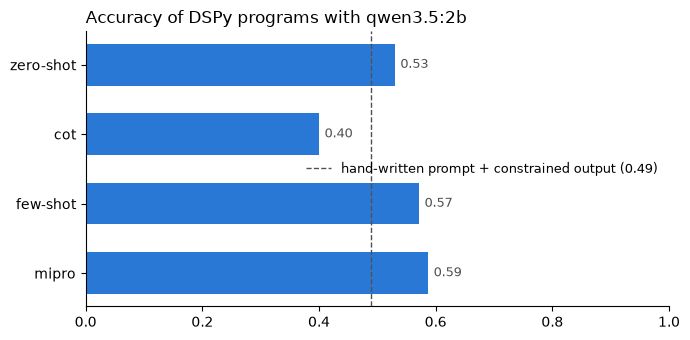

In [7]:
fig, ax = plt.subplots(figsize=(7, 3.5))
bars = ax.barh(dspy_summary["program"], dspy_summary["accuracy"], color="#2a78d6", height=0.6)
for bar, value in zip(bars, dspy_summary["accuracy"]):
    ax.annotate(f"{value:.2f}", (value, bar.get_y() + bar.get_height() / 2), textcoords="offset points",
                xytext=(4, 0), va="center", fontsize=9, color="#52514e")
ax.axvline(reference, color="#52514e", linestyle="--", linewidth=1,
           label=f"hand-written prompt + constrained output ({reference:.2f})")
ax.legend(frameon=False, loc="center right", fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1)
ax.set_title(f"Accuracy of DSPy programs with {TASK_MODEL}", loc="left")
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout()

In [8]:
# Re-evaluate a saved program yourself (LM calls are cached by DSPy, so this is fast when repeated)
evaluate_program(mipro, testset[:40])

  0%|          | 0/40 [00:00<?, ?it/s]

Average Metric: 1.00 / 1 (100.0%):   0%|          | 0/40 [00:00<?, ?it/s]

Average Metric: 1.00 / 1 (100.0%):   2%|▎         | 1/40 [00:00<00:29,  1.33it/s]

Average Metric: 1.00 / 2 (50.0%):   2%|▎         | 1/40 [00:01<00:29,  1.33it/s] 

Average Metric: 1.00 / 2 (50.0%):   5%|▌         | 2/40 [00:01<00:25,  1.51it/s]

...

Average Metric: 21.00 / 40 (52.5%):  98%|█████████▊| 39/40 [00:21<00:00,  1.89it/s]

Average Metric: 21.00 / 40 (52.5%): 100%|██████████| 40/40 [00:21<00:00,  1.89it/s]

Average Metric: 21.00 / 40 (52.5%): 100%|██████████| 40/40 [00:21<00:00,  1.87it/s]

2026/10/11 08:28:57 INFO dspy.evaluate.evaluate: Average Metric: 21 / 40 (52.5%)


{'n': 40,
 'accuracy': np.float64(0.525),
 'invalid_rate': np.float64(0.0),
 'wall_time_s': 21.389282026997535}